# Example - 2CDE Method

*This notebook is part of a tutorial series showing how to migrate from FRETBurts to [smfBursts](https://github.com/OpenSMFS/smfBursts).*

> This notebook implements the 2CDE method from [Tomov 2012](https://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025).
>
> For a complete tutorial on smfBursts based burst analysis see 
> [Bursts Tutorial](BurstsTutorial.ipynb).</s>
>
> Lines from the original notebook are commented out, with equivalent commands presented below.
>
> Additional clarification is added throughout the notebook.

In [1]:
# from fretbursts import *
# from fretbursts.phtools import phrates
# sns = init_notebook(apionly=True)
# import fretbursts
# sns.__version__, fretbursts.__version__

import numpy as np
import matplotlib.pyplot as plt

import smfbursts as smf
smf.__version__

'0.3.0'

In [2]:
# Tweak here matplotlib style
import matplotlib as mpl
mpl.rcParams['font.sans-serif'].insert(0, 'Arial')
mpl.rcParams['font.size'] = 12
%config InlineBackend.figure_format = 'retina'

## Load Data

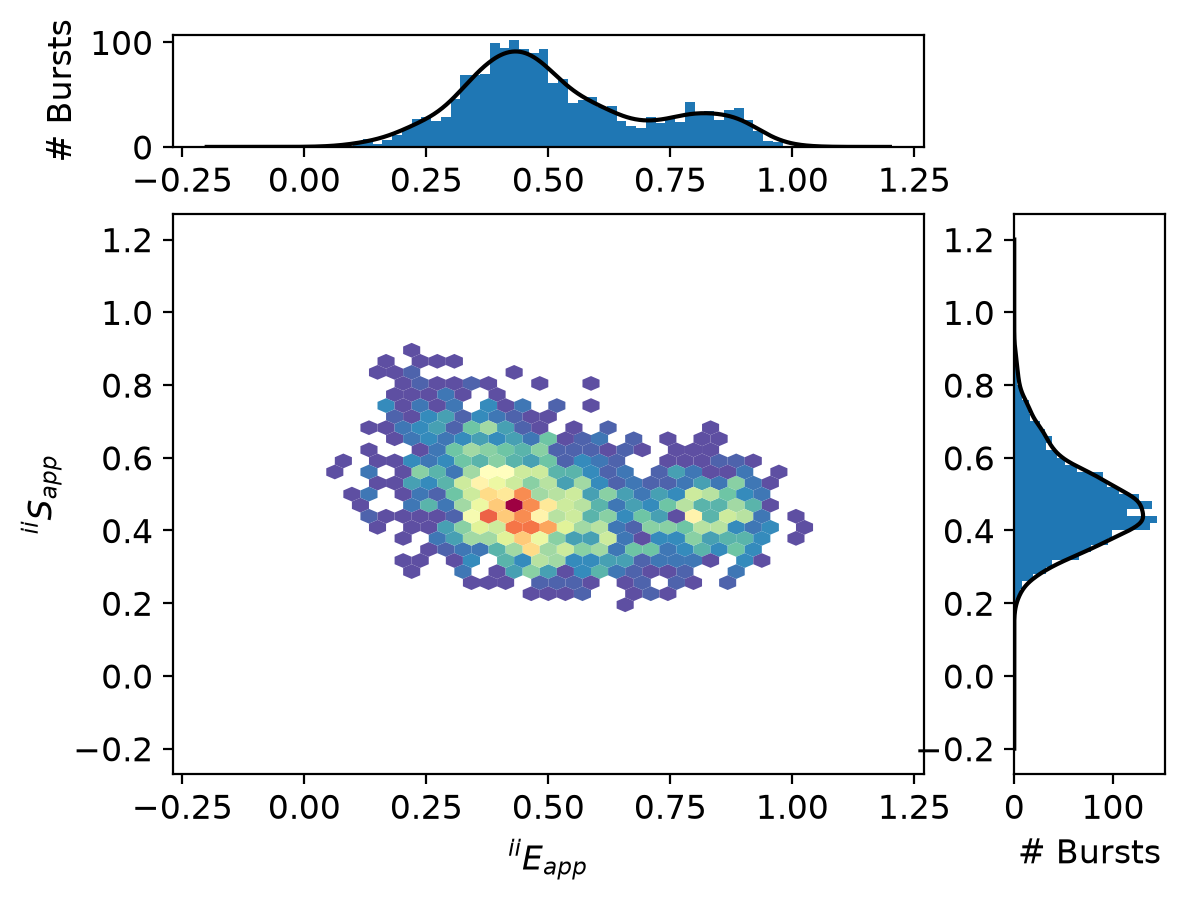

In [3]:
# url = 'http://files.figshare.com/2182601/0023uLRpitc_NTP_20dT_0.5GndCl.hdf5'
# download_file(url, save_dir='./data')

## use pooch to download from new url instead
## repo = pooch.create(path='data', base_url='doi:10.5281/zenodo.20038738')
## repo.load_registry_from_doi()

filename = "data/0023uLRpitc_NTP_20dT_0.5GndCl.hdf5"

## if downloading, fecth with pooch
## repo.fetch(filename.split('/')[-1])

# d = loader.photon_hdf5(filename)
raw = smf.hdf5.load(filename)
# loader.alex_apply_period(d)
data = smf.hdf5.regularize_dets(raw)
# d.calc_bg(fun=bg.exp_fit, time_s=20, tail_min_us='auto', F_bg=1.7)
bg = smf.ff.make_bg(data, period=20.0, func=smf.bg.exp_mlefit, 
                    tail_min=5e-4, auto_threshold=True, F_bg=1.7)
# d.burst_search()
bursts = smf.ff.make_burst_search(bg=bg['bg'], m=10, F=6.0, streams=smf.PhSel('0ex_1ex1em'))

# ds1 = d.select_bursts(select_bursts.size, th1=30)
gDD = smf.make_geq_gate(bursts['NphDex_bg'], 30.0)
# ds = ds1.select_bursts(select_bursts.naa, th1=30)
gAA = smf.make_geq_gate(bursts['NphAA_bg'], 30.0)
gMain = gDD & gAA

# alex_jointplot(ds)
cplot_kwargs= smf.ff.AD['hexbin', ('cmap', 'Spectral_r')]
hplot_kwargs={'bins':smf.ff.AD['ratio_bins'], 'kdeplot_kwargs':{'c':'k'}}

smf.plot.jointplot(data, bursts['E_bg'], bursts['S_bg'], gate=gMain,
                   cfunc=smf.plot.hexbin, cplot_kwargs=cplot_kwargs,
                   hfunc=smf.plot.hist_kdeoverlay, hplot_kwargs=hplot_kwargs,);

## KDE considerations

In computing a KDE, the kernel can have different shapes. In the original
2CDE publication the "laplace distribution" kernel is used.

In the next sections we will show the 2CDE results
using both "laplace distribution" Gaussian kernel.

Here, we simply plot the two kernels for comparison:

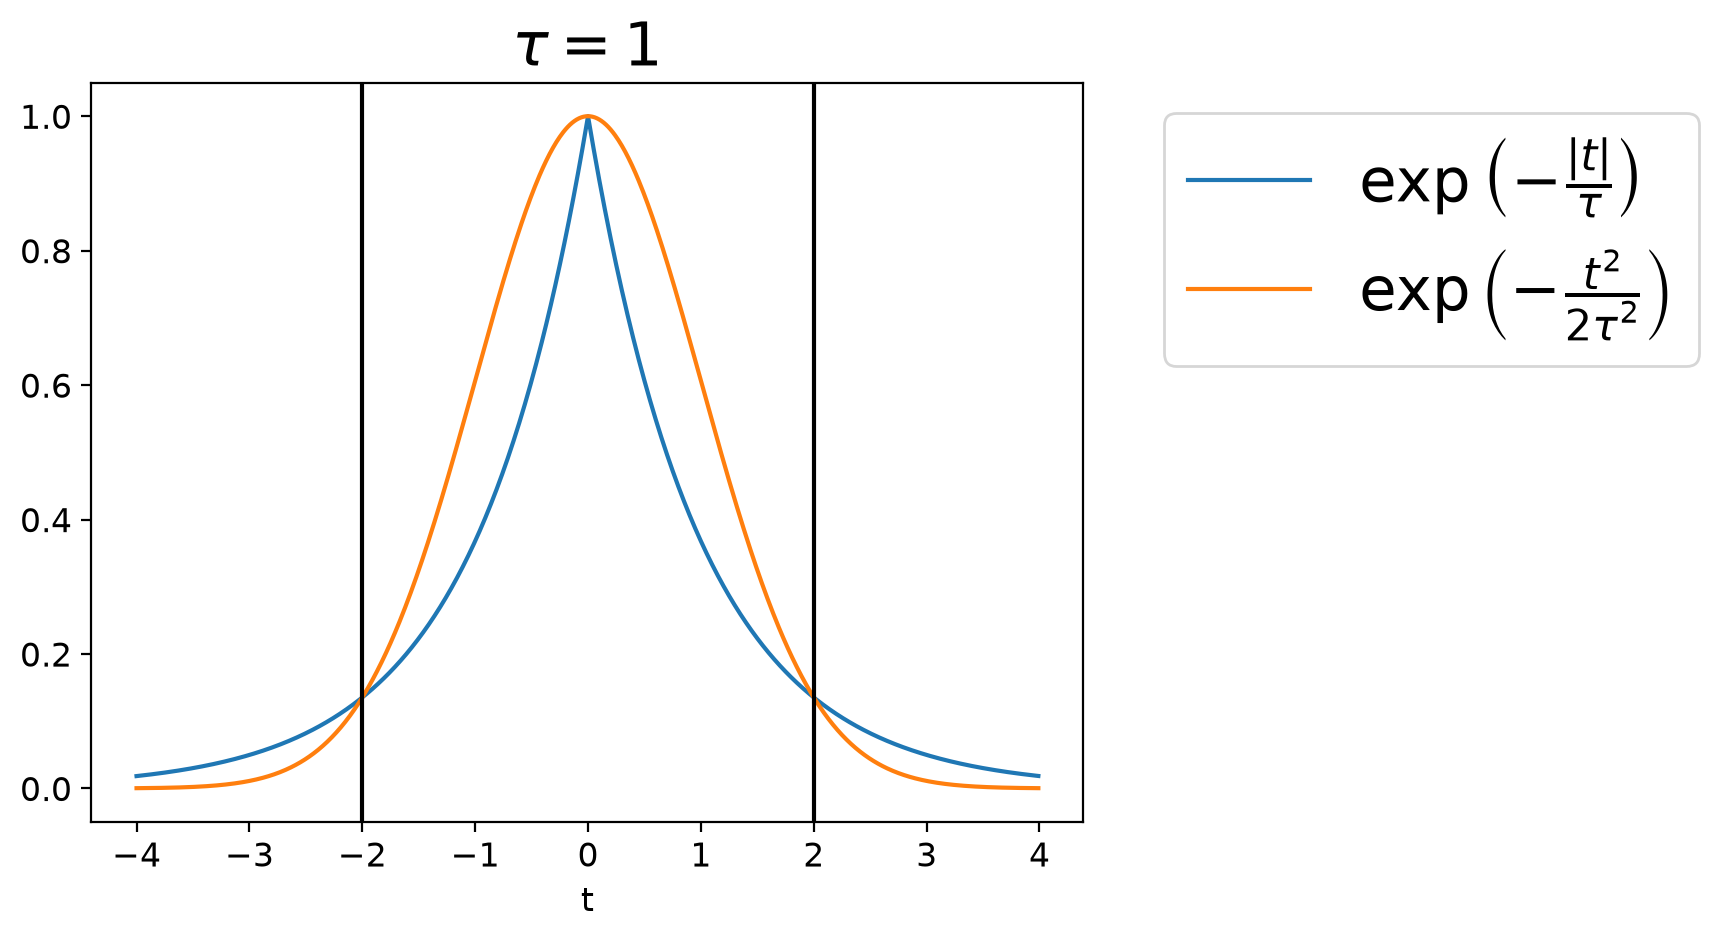

In [4]:
tau = 1.0
tau_sq = 2.0 * (tau**2)

xx = np.arange(-4*tau, 4*tau, tau/100.)
y1 = np.exp(-np.abs(xx) / tau)
y2 = np.exp(-xx**2 / tau_sq)

plt.plot(xx,y1, label=r'$\exp \left( - \frac{|t|}{\tau} \right)$')
plt.plot(xx, y2, label=r'$\exp \left( - \frac{t^2}{2\tau^2} \right)$')
plt.axvline(2*tau, color='k')
plt.axvline(-2*tau, color='k')
plt.xlabel('t')
plt.legend(fontsize=22, bbox_to_anchor=(1.05, 1), loc=2)
plt.title(r'$\tau = %d$' % tau, fontsize=22);

## Notes on Kernel Shape

The Gaussian kernel gives a more accurate rate estimation with very little dependence on the position where the KDE is evaluated. On the contrary, with symmetric exponential kernel (laplace distribution), there is always a strong dependence on the evaluation position. In particular, when rates are estimated at the timestamps positions, the rates are systematically over-estimated (i.e. the peak is always sampled).

For a Gaussian kernel, given a $\tau$, the rate estimation will be accurate for rates higher than $1/(2\,\tau)$ counts-per-second. For lower rates, the estimation will strongly depend on where the KDE is evaluated. A similar condition can be also found for the exponential kernel, but this case the rate will aways be strongly dependent on the position.

## 2CDE

### KDE and nbKDE Definitions

Following Tomov 2012 notation, we define *KDE* as ([Tomov 2012, eq. 4](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$KDE_{X_i}^Y \left(t_{(CHX)_i}, t_{\{CHY\}} \right) = 
\sum_j^{N_{CHY}} \exp \left( - \frac{\lvert t_{(CHX)_i} - t_{(CHY)_j} \rvert}{\tau}\right) $$

and *nbKDE* as ([Tomov 2012, eq. 5](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$nbKDE_{X_i}^X \left(t_{\{CHX\}} \right) = \left(1 + \frac{2}{N_{CHX}} \right) \cdot
\sum_{j, \;j\ne i}^{N_{CHX}} \exp \left( - \frac{\lvert t_{(CHX)_i} - t_{(CHX)_j} \rvert}{\tau}\right) $$

These quantities can be computed for any slice of the timestamp arrays. 
In the implementation of *FRET-2CDE*, they will be computed on slices of
timestamps corresponding to each burst. 
In this context, $N_{CHX}$, (in the multiplicative correction factor of nbKDE), 
is the number of photons in the current burst (selecting only photons in the $X$ channel).

### FRET-2CDE Definition

To compute FRET-2CDE we need to define ([Tomov 2012, eq. 6](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$(E)_D = \frac{1}{N_{CHD}} \sum_{i=1}^{N_{CHD}} \frac{KDE_{Di}^A}{KDE_{Di}^A + nbKDE_{Di}^D} $$

and the symmetric estimator ([Tomov 2012, eq. 7](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$(1 - E)_A = \frac{1}{N_{CHA}} \sum_{i=1}^{N_{CHA}} \frac{KDE_{Ai}^D}{KDE_{Ai}^D + nbKDE_{Ai}^A} $$

Then *FRET-2CDE* is defined as ([Tomov 2012, eq. 8](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$ FRET-2CDE \left( t_{CHD}, t_{CHA} \right) = 
110 - 100 \cdot \left[ (E)_D + (1 - E)_A \right]
$$

These quantities are computed for each burst, so that $N_{CHD}$ ($N_{CHA}$) are
the number of photons in the DexDem (AemDex) channel during current burst.

### FRET-2CDE Functions

<s>To implement the *FRET-2CDE*, we use the following FRETBursts function:</s>

- <s>`phrates.kde_laplace()` ([documentation](http://fretbursts.readthedocs.org/en/latest/phrates.html#fretbursts.phtools.phrates.kde_laplace))</s>

<s>This function computes the local photon rate using KDE with a [laplace distribution](https://en.wikipedia.org/wiki/Laplace_distribution) kernel. 
FRETBursts provides similar functions to use a Gaussian or rectangular kernel ([kde_gaussian](http://fretbursts.readthedocs.org/en/latest/phrates.html#fretbursts.phtools.phrates.kde_gaussian) and
[kde_rect](http://fretbursts.readthedocs.org/en/latest/phrates.html#fretbursts.phtools.phrates.kde_rect)
respectively).</s>

<s>Here we define two functions to compute *FRET-2CDE* using the **laplace kernel**
(as in the original paper) and **Gaussian kernel**:</s>

The kernel functions are implemented direclty in smfBursts, in the `smf.cpt.laplace_kde` and `smf.cpt.gaussian_kde`.

In [5]:
# def calc_fret_2cde(tau, ph, mask_d, mask_a, bursts):
#     """
#     Compute FRET-2CDE for each burst.

#     FRET-2CDE is a quantity that tends to be around 10 for bursts which have no
#     dynamics, while it has larger values (e.g. 30..100) for bursts with
#     millisecond dynamics.

#     References:
#         Tomov et al. BJ (2012) doi:10.1016/j.bpj.2011.11.4025

#     Arguments:
#         tau (scalar): time-constant of the exponential KDE
#         ph (1D array): array of all-photons timestamps.
#         mask_d (bool array): mask for DexDem photons
#         mask_a (bool array): mask for DexAem photons
#         bursts (Bursts object): object containing burst data
#             (start-stop indexes are relative to `ph`).

#     Returns:
#         FRET_2CDE (1D array): array of FRET_2CDE quantities, one element
#             per burst. This array contains NaN in correspondence of bursts
#             containing to few photons to compute FRET-2CDE.
#     """
#     # Computing KDE burst-by-burst would cause inaccuracies at the burst edges.
#     # Therefore, we first compute KDE on the full timestamps array and then
#     # we take slices for each burst.
#     # These KDEs are evaluated on all-photons array `ph` (hence the Ti suffix)
#     # using D or A photons during D-excitation (argument ph[mask_d] or ph[mask_a]).
#     KDE_DTi = phrates.kde_laplace(ph[mask_d], tau, time_axis=ph)
#     KDE_ATi = phrates.kde_laplace(ph[mask_a], tau, time_axis=ph)

#     FRET_2CDE = []
#     for ib, burst in enumerate(bursts):
#         burst_slice = slice(int(burst.istart), int(burst.istop) + 1)
#         if ~mask_d[burst_slice].any() or ~mask_a[burst_slice].any():
#             # Either D or A photon stream has no photons in current burst,
#             # thus FRET_2CDE cannot be computed. Fill position with NaN.
#             FRET_2CDE.append(np.nan)
#             continue

#         # Take slices of KDEs for current burst
#         kde_adi = KDE_ATi[burst_slice][mask_d[burst_slice]]
#         kde_ddi = KDE_DTi[burst_slice][mask_d[burst_slice]]
#         kde_dai = KDE_DTi[burst_slice][mask_a[burst_slice]]
#         kde_aai = KDE_ATi[burst_slice][mask_a[burst_slice]]

#         # nbKDE does not include the "center" timestamp which contributes 1.
#         # We thus subtract 1 from the precomputed KDEs.
#         # The N_CHD (N_CHA) value in the correction factor is the number of
#         # timestamps in DexDem (DexAem) stream falling within the current burst.
#         N_CHD = mask_d[burst_slice].sum()
#         N_CHA = mask_a[burst_slice].sum()
#         nbkde_ddi = (1 + 2/N_CHD) * (kde_ddi - 1)
#         nbkde_aai = (1 + 2/N_CHA) * (kde_aai - 1)

#         # N_CHD (N_CHA) in eq. 6 (eq. 7) of (Tomov 2012) is the number of photons
#         # in DexDem (DexAem) in current burst. Thus the sum is a mean.
#         ED = np.mean(kde_adi / (kde_adi + nbkde_ddi))  # (E)_D
#         EA = np.mean(kde_dai / (kde_dai + nbkde_aai))  # (1 - E)_A

#         # Compute fret_2cde for current burst
#         fret_2cde = 110 - 100 * (ED + EA)
#         FRET_2CDE.append(fret_2cde)
#     return np.array(FRET_2CDE)

In [6]:
# def calc_fret_2cde_gauss(tau, ph, mask_d, mask_a, bursts):
#     """
#     Compute a modification of FRET-2CDE using a Gaussian kernel.
    
#     Reference: Tomov et al. BJ (2012) doi:10.1016/j.bpj.2011.11.4025
    
#     Instead of using the exponential kernel (i.e. laplace distribution)
#     of the original paper, here we use a Gaussian kernel.
#     Photon density using Gaussian kernel provides a smooth estimate
#     regardless of the evaluation time. On the contrary, the 
#     laplace-distribution kernel has discontinuities in the derivative 
#     (cuspids) on each time point corresponding to a timestamp.
#     Using a Gaussian kernel removes the need of using the heuristic 
#     correction (pre-factor) of nbKDE.
    
#     Arguments:
#         tau (scalar): time-constant of the exponential KDE
#         ph (1D array): array of all-photons timestamps.
#         mask_d (bool array): mask for DexDem photons
#         mask_a (bool array): mask for DexAem photons
#         bursts (Bursts object): object containing burst data
        
#     Returns:
#         FRET_2CDE (1D array): array of FRET_2CDE quantities, one element 
#             per burst. This array contains NaN in correspondence of bursts 
#             containing to few photons to compute FRET-2CDE.
#     """
#     # Computing KDE burst-by-burst would cause inaccuracies at the edges
#     # So, we compute KDE for the full timestamps
#     KDE_DTi = phrates.kde_gaussian(ph[mask_d], tau, time_axis=ph)
#     KDE_ATi = phrates.kde_gaussian(ph[mask_a], tau, time_axis=ph)

#     FRET_2CDE = []
#     for ib, burst in enumerate(bursts):
#         burst_slice = slice(int(burst.istart), int(burst.istop) + 1)
#         if ~mask_d[burst_slice].any() or ~mask_a[burst_slice].any():
#             # Either D or A photon stream has no photons in current burst, 
#             # thus FRET_2CDE cannot be computed.
#             FRET_2CDE.append(np.nan)
#             continue

#         kde_ddi = KDE_DTi[burst_slice][mask_d[burst_slice]]
#         kde_adi = KDE_ATi[burst_slice][mask_d[burst_slice]]    
#         kde_dai = KDE_DTi[burst_slice][mask_a[burst_slice]]
#         kde_aai = KDE_ATi[burst_slice][mask_a[burst_slice]]
        
#         ED = np.mean(kde_adi / (kde_adi + kde_ddi))  # (E)_D
#         EA = np.mean(kde_dai / (kde_dai + kde_aai))  # (1 - E)_A

#         fret_2cde = 110 - 100 * (ED + EA)
#         FRET_2CDE.append(fret_2cde)
#     return np.array(FRET_2CDE)

## FRET-2CDE Results

Let's define $\tau$, the kernel parameter which defines the "time range"
of the photon density estimation:

> **Note**
>
> tau will be a parameter in the `smf.KDE` `smf.Param`
> The conversion from seconds to the photon clock time
> is handled by `smf.KDE`/`smf.PhotonData`, and thus the conversion
> in the FRETbursts version becomes irrelevant

In [7]:
tau = 50e-6             # in seconds
# tau = int(tau_s/d.clk_p)  # in raw timestamp units
tau

5e-05

<s>Next, we get the timestamps and selection masks for DexDem and DexAem photon streams,
as well as the burst data:</s>

These calculations are now handeled by `smf.KDE`, and so extracting these arrays is irrelevant.

In [8]:
# ph = d.get_ph_times(ph_sel=Ph_sel('all'))
# mask_d = d.get_ph_mask(ph_sel=Ph_sel(Dex='Dem'))
# mask_a = d.get_ph_mask(ph_sel=Ph_sel(Dex='Aem'))

# bursts = ds.mburst[0]

We can finally compute the *FRET-2CDE* for each burst:

Compared with FRETBursts, where we take many small steps, here we define the
`smf.Param` and the `smf.Column` that define our kernel and the FRET2CDE arrays respectively

In [9]:
# fret_2cde = calc_fret_2cde(tau, ph, mask_d, mask_a, bursts)

# define the Laplace based Param, _l in names is for laplace
kde_l = smf.Param(smf.KDE, base=bursts['bursts'], all_phot=False, exclude_zero=True,
                  tau=tau, kernel=smf.cpt.laplace_kde)

# define the column, note we need to define the DexDex and DexAem streams
Fret2CDE_l = smf.Column(kde_l, 'fret2cde', 
                        (smf.PhSel('0ex0em'), smf.PhSel('0ex1em')))

fret_2cde_l = data.get_column(Fret2CDE_l, gate=gMain)

In [10]:
fret_2cde_l

array([22.76770404,  9.1933803 , 13.51002384, ..., 22.36161142,
       20.33424353, -8.57757069], shape=(1757,))

In [11]:
def my_kernel(delta, tau):
    return tau / (np.abs(delta) + 1)
my_kernel.name = r'\mathcal{Y}'
my_kernel.thresh_func = lambda param: 5.0*param.get('tau')

smf.cpt.register_kde_func(my_kernel, smf.datamodel.ParamDef('tau', smf.datamodel.TV_float(mn=0.0)))

In [12]:
kde_m = smf.Param(smf.KDE, base=bursts['bursts'], tau=5e-5, kernel=my_kernel)

In [13]:
fret2cde_m = smf.Column(kde_m, 'fret2cde', (smf.PhSel('0ex0em'), smf.PhSel('0ex1em')))

In [14]:
data.get_column(fret2cde_m)

array([109.00399271, 109.94862223,          nan, ..., 109.92943285,
       109.99196082, 109.97250664], shape=(17313,))

In [15]:
# fret_2cde_gauss = calc_fret_2cde_gauss(tau, ph, mask_d, mask_a, bursts)

# define the Gaussian based Param, _g in names is for gaussian
# note the different value of kernel in the param compared to the previous cell
kde_g = smf.Param(smf.KDE, base=bursts['bursts'], 
                  sigma=tau, kernel=smf.cpt.gaussian_kde)

# define the column, note we need to define the DexDex and DexAem streams
Fret2CDE_g = smf.Column(kde_g, 'fret2cde', 
                        (smf.PhSel('0ex0em'), smf.PhSel('0ex1em')))

fret_2cde_g = data.get_column(Fret2CDE_g, gate=gMain)

In [16]:
s = f"""
Number of bursts: {fret_2cde_l.size}
Laplace cde values (valid): {len(fret_2cde_l)} ({(np.isfinite(fret_2cde_l)).sum()})
Gaussian cde values (valid): {len(fret_2cde_g)} ({(np.isfinite(fret_2cde_g)).sum()})
"""
print(s)


Number of bursts: 1757
Laplace cde values (valid): 1757 (1748)
Gaussian cde values (valid): 1757 (1757)



And visualize the results with some plots:

In [17]:
# def plot_kde(values):
#     valid = np.isfinite(values)
#     x, y = ds.E[0][valid], values[valid]
#     fig = plt.figure(figsize=(4.5, 4.5))
#     sns.kdeplot(x=x, y=y,
#                 cmap='Spectral_r', fill=True, thresh=0.05, n_levels=20)
#     plt.xlabel('E', fontsize=16)
#     plt.ylabel('FRET-2CDE', fontsize=16)
#     plt.ylim(-10, 50)
#     plt.axhline(10, ls='--', lw=2, color='k')
#     plt.text(0.05, 0.95, '2CDE', va='top', fontsize=22, transform=plt.gca().transAxes)
#     plt.text(0.95, 0.95, '# Bursts: %d' % valid.sum(), 
#             va='top', ha='right', transform=plt.gca().transAxes)
#     return fig

kde_kwargs = {'cmap':'Spectral_r', 'thresh':0.05}

In [18]:
print(Fret2CDE_l.description)

Column: KDE, fret2cde, 0ex0em, 0ex1em
  Params:
    kernel: smfbursts.childphotontables.laplace_kde
    thresh: 0.00025
    all_phot: False
    exclude_zero: True
    tau: 5e-05
  Parents:
    base:  Table: Bursts
      Params:
        func: smfbursts.bursttables.burstsearch_mwindowF_bg
        stream: 0ex_1em
        m: 10
        F: 6.0
        c: -1.0
        fuse: 0.0
      Parents:
        bg:  Table: BG
          Params:
            compute_stream: single_all
            func: smfbursts.backgroundtables.exp_mlefit
            tail_min: [0.0005 0.0005 0.0005 0.0005 0.0005]
            auto_threshold: True
            F_bg: 1.7
          Parents:
            base:  Table: Periods
              Params:
                period: 20.0
                start_at: time_min
                stop_at: over
                detdef: DetDef2ex2em


(-10.0, 50.0)

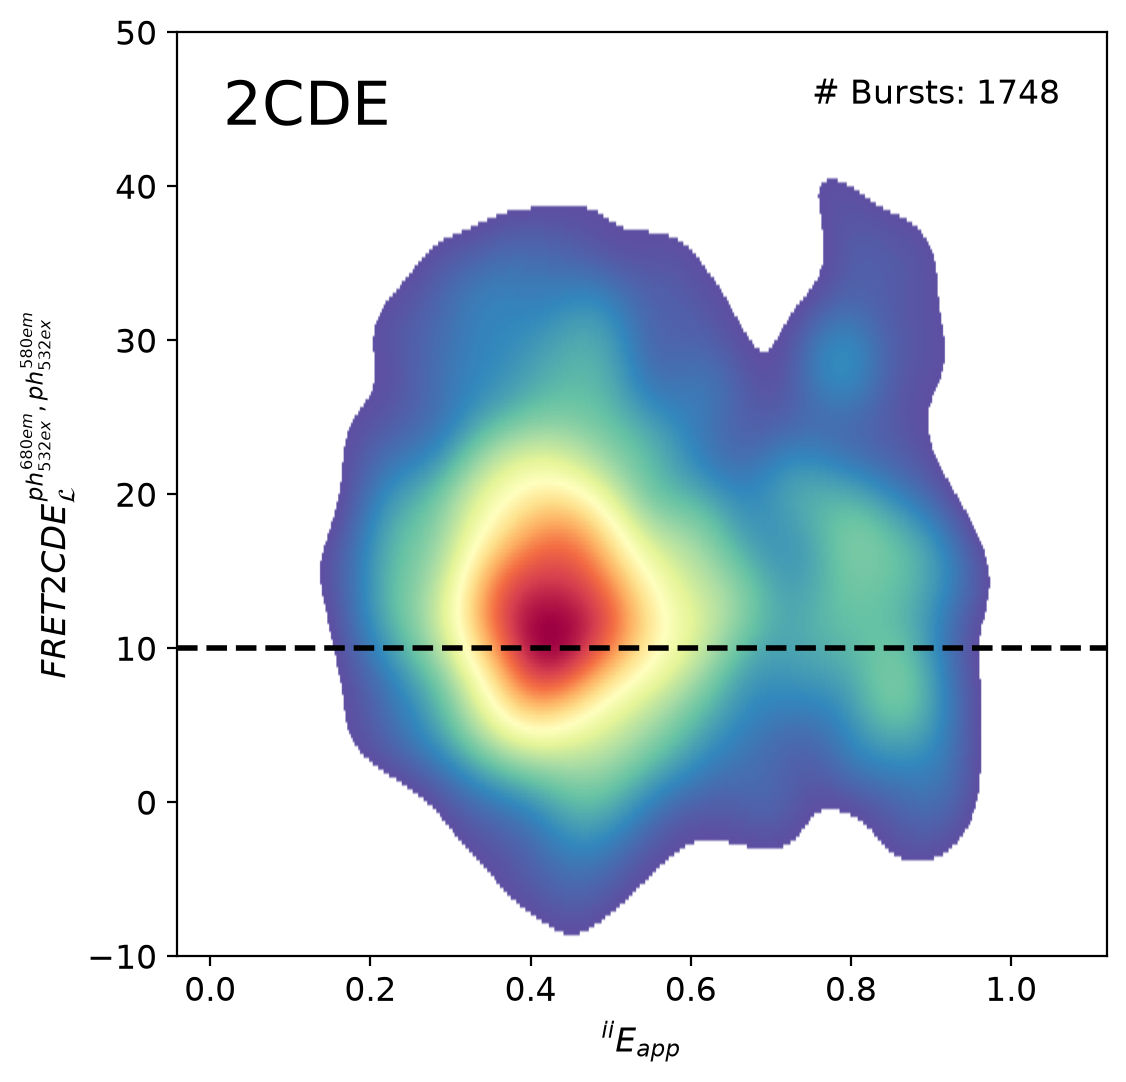

In [19]:
# fig = plot_kde(fret_2cde)
fig, ax = plt.subplots(figsize=(6,6))

smf.plot.kdeplot(data, bursts['E_bg'], Fret2CDE_l, gate=gMain, 
                 ax=ax, **kde_kwargs)
# ax.set_ylim([-10, 50])
ax.axhline(10, ls='--', lw=2, color='k')
ax.text(0.05, 0.95, '2CDE', va='top', fontsize=22, transform=ax.transAxes)
nburst = np.isfinite(data.get_column(Fret2CDE_l, gate=gMain)).sum()
ax.text(0.95, 0.95, f'# Bursts: {nburst}', 
        va='top', ha='right', transform=plt.gca().transAxes)
ax.set_ylim([-10, 50])
# Uncommented lines below to save figure (change filename if necessary)
# fig.savefig('2cde_laplace.png', bbox_inches='tight', 
#             dpi=200, transparent=False)

(-10.0, 50.0)

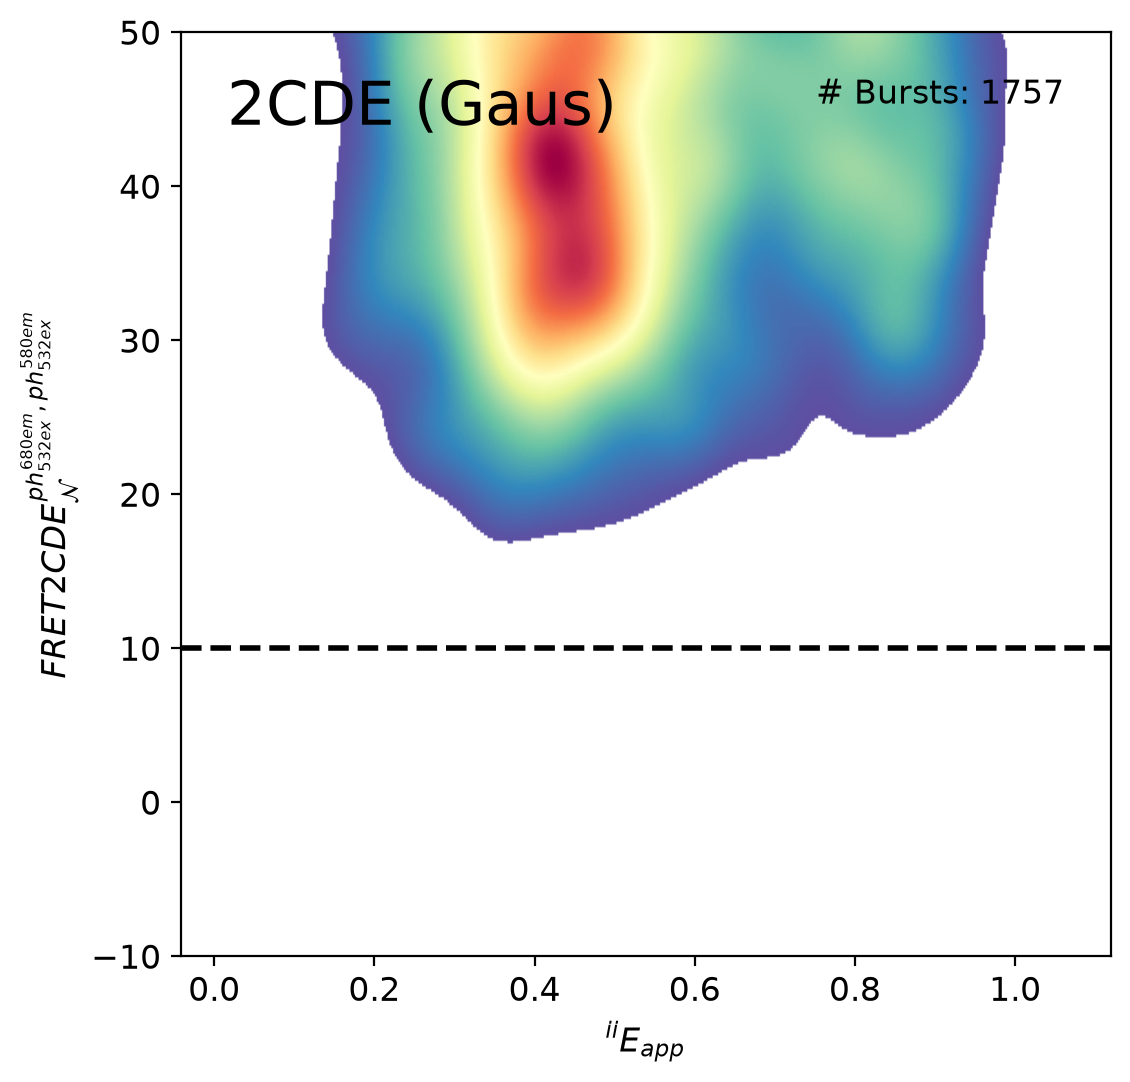

In [20]:
# fig = plot_kde(fret_2cde_gauss)
fig, ax = plt.subplots(figsize=(6,6))

smf.plot.kdeplot(data, bursts['E_bg'], Fret2CDE_g, gate=gMain, 
                 ax=ax, **kde_kwargs)
ax.axhline(10, ls='--', lw=2, color='k')
ax.text(0.05, 0.95, '2CDE (Gaus)', va='top', fontsize=22, transform=ax.transAxes)
nburst = np.isfinite(data.get_column(Fret2CDE_g, gate=gMain)).sum()
ax.text(0.95, 0.95, f'# Bursts: {nburst}', 
        va='top', ha='right', transform=plt.gca().transAxes)
ax.set_ylim([-10, 50])

# suggeted means to save the figure
# fig.savefig('2cde_gauss.png', bbox_inches='tight', dpi=200, transparent=False)

## ALEX-2CDE Definition

To compute ALEX-2CDE we need to define ([Tomov 2012, eq. 10](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$BR_{D_{EX}} = \frac{1}{ N_{CHA_{EX}} } 
\sum_{i=1}^{N_{CHD_{EX}}} \frac{ KDE_{D_{EX}i}^A }{ KDE_{D_{EX}i}^D }$$

and the analogous ([Tomov 2012, eq. 11](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$BR_{A_{EX}} = \frac{1}{ N_{CHD_{EX}} } 
\sum_{i=1}^{N_{CHA_{EX}}} \frac{ KDE_{A_{EX}i}^D }{ KDE_{A_{EX}i}^A }$$

Finally, *ALEX-2CDE* is defined as ([Tomov 2012, eq. 12](http://dx.doi.org/10.1016%2Fj.bpj.2011.11.4025)):

$$ ALEX-2CDE \left( t_{CHD}, t_{CHA} \right) = 
110 - 50 \cdot \left[ BR_{D_{EX}} + BR_{A_{EX}} \right]
$$


### ALEX-2CDE Implementation

In [21]:
# bursts = ds1.mburst[0]

# ph_dex = d.get_ph_times(ph_sel=Ph_sel(Dex='DAem'))
# ph_aex = d.get_ph_times(ph_sel=Ph_sel(Aex='Aem'))

# mask_dex = d.get_ph_mask(ph_sel=Ph_sel(Dex='DAem'))
# mask_aex = d.get_ph_mask(ph_sel=Ph_sel(Aex='Aem'))

# KDE_DexTi = phrates.kde_laplace(ph_dex, tau, time_axis=ph)
# KDE_AexTi = phrates.kde_laplace(ph_aex, tau, time_axis=ph)

# ALEX_2CDE = []
# BRDex, BRAex = [], []
# for ib, burst in enumerate(bursts):
#     burst_slice = slice(int(burst.istart), int(burst.istop) + 1)
#     if ~mask_dex[burst_slice].any() or ~mask_aex[burst_slice].any():
#         # Either D or A photon stream has no photons in current burst, 
#         # thus ALEX_2CDE cannot be computed.
#         ALEX_2CDE.append(np.nan)
#         continue

#     kde_dexdex = KDE_DexTi[burst_slice][mask_dex[burst_slice]]
#     kde_aexdex = KDE_AexTi[burst_slice][mask_dex[burst_slice]]
#     N_chaex = mask_aex[burst_slice].sum()
#     BRDex.append(np.sum(kde_aexdex / kde_dexdex) / N_chaex)
    
#     kde_aexaex = KDE_AexTi[burst_slice][mask_aex[burst_slice]]
#     kde_dexaex = KDE_DexTi[burst_slice][mask_aex[burst_slice]]
#     N_chdex = mask_dex[burst_slice].sum()
#     BRAex.append(np.sum(kde_dexaex / kde_aexaex) / N_chdex)
    
#     alex_2cde = 100 - 50*(BRDex[-1] + BRAex[-1])
#     ALEX_2CDE.append(alex_2cde)
# ALEX_2CDE = np.array(ALEX_2CDE)

Alex2CDE_l = smf.Column(kde_l, 'alex2cde', (smf.PhSel('0ex'), smf.PhSel('1ex1em')))
ALEX_2CDE_l = data.get_column(Alex2CDE_l, gate=gDD)

In [22]:
# ALEX_2CDE.size, np.isfinite(ALEX_2CDE).sum(), np.isfinite(ds1.E[0]).sum()
ALEX_2CDE_l.size, np.isfinite(ALEX_2CDE_l).sum(), np.isfinite(data.get_column(bursts['E_bg'], gate=gDD)).sum()

(3224, np.int64(3092), np.int64(3224))

And some final plots of *ALEX-2CDE*:

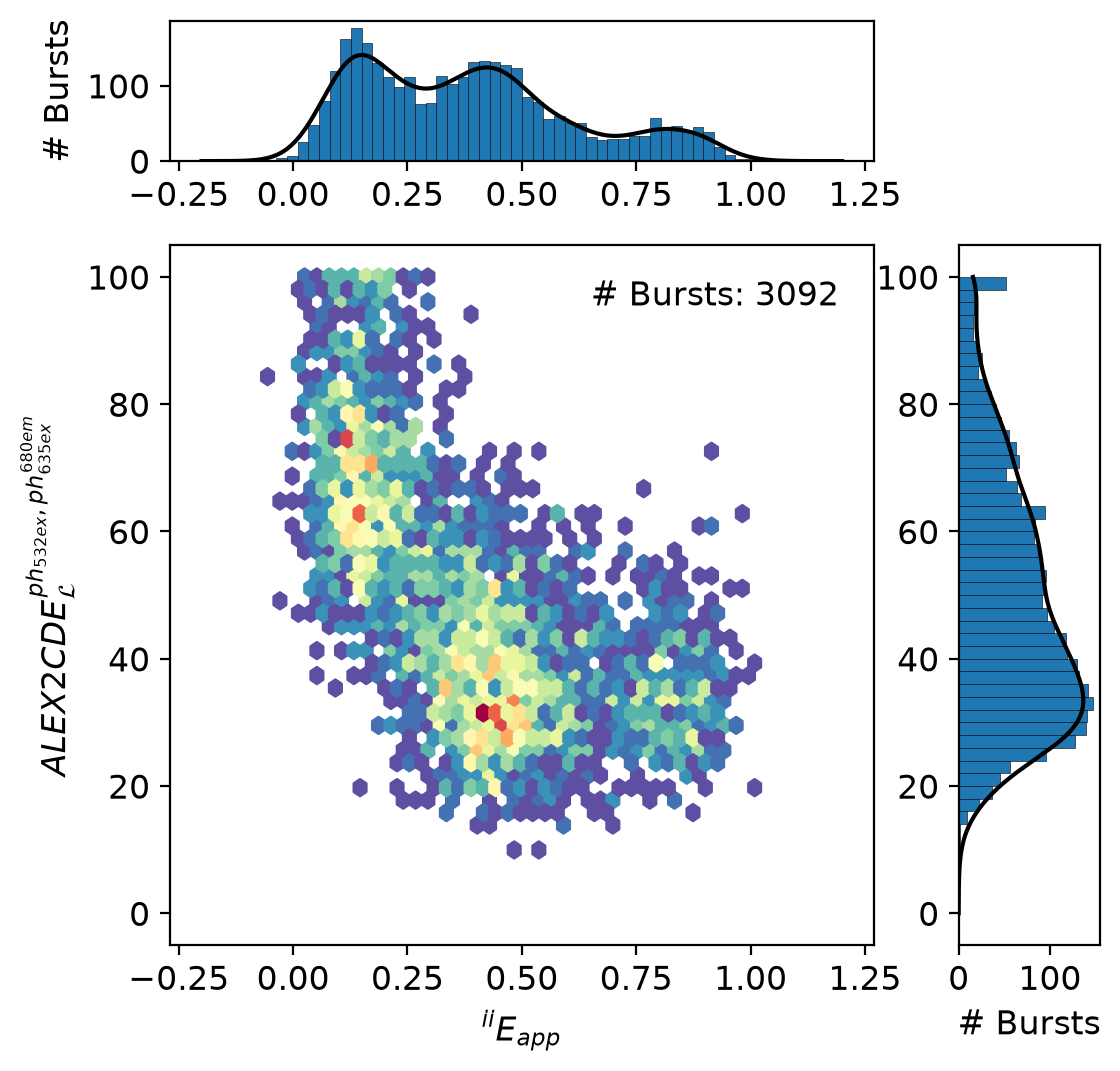

In [23]:
# hist_kws = dict(edgecolor='k', linewidth=0.2,
#                 facecolor=sns.color_palette('Spectral_r', 100)[7])
# valid = np.isfinite(ALEX_2CDE)
# g = sns.JointGrid(x=ds1.E[0][valid], y=ALEX_2CDE[valid], ratio=3)
# g = g.plot_joint(plt.hexbin, **{'cmap': 'Spectral_r', 'mincnt': 1, 'gridsize': 40})
# _ = g.ax_marg_x.hist(ds1.E[0][valid], bins=np.arange(-0.2, 1.2, 0.0333), **hist_kws)
# _ = g.ax_marg_y.hist(ALEX_2CDE[valid], bins=40, orientation="horizontal", **hist_kws)
# g.ax_joint.set_xlabel('E', fontsize=16)
# g.ax_joint.set_ylabel('ALEX-2CDE', fontsize=16);
# g.ax_joint.text(0.95, 0.95, '# Bursts: %d' % valid.sum(), 
#                 va='top', ha='right', transform=g.ax_joint.transAxes);

fig = plt.figure(figsize=(6,6))
# kwargs for central plot, 
alex_hexbin_kwargs = {'cmap':'Spectral_r', 'mincnt':1, 'gridsize':40}
hist_kwargs = {'edgecolor':'k', 'linewidth':0.2, 'kdeplot_kwargs':{'c':'k'}}
xhist_kwargs = {'bins':np.linspace(-0.2, 1.2, 61)}
yhist_kwargs = {'bins':np.linspace(0, 100, 51)}

jp = smf.plot.jointplot(data, bursts['E_bg'], Alex2CDE_l, gate=gDD,
                        cfunc=smf.plot.hexbin, hfunc=smf.plot.hist_kdeoverlay,
                        cplot_kwargs=alex_hexbin_kwargs, 
                        hplot_kwargs=hist_kwargs, 
                        xplot_kwargs=xhist_kwargs, yplot_kwargs=yhist_kwargs)

nburst = np.isfinite(data.get_column(Alex2CDE_l, gate=gDD)).sum()
jp[0][0].text(0.95, 0.95, f'# Bursts: {nburst}', 
              va='top', ha='right', transform=jp[0][0].transAxes);

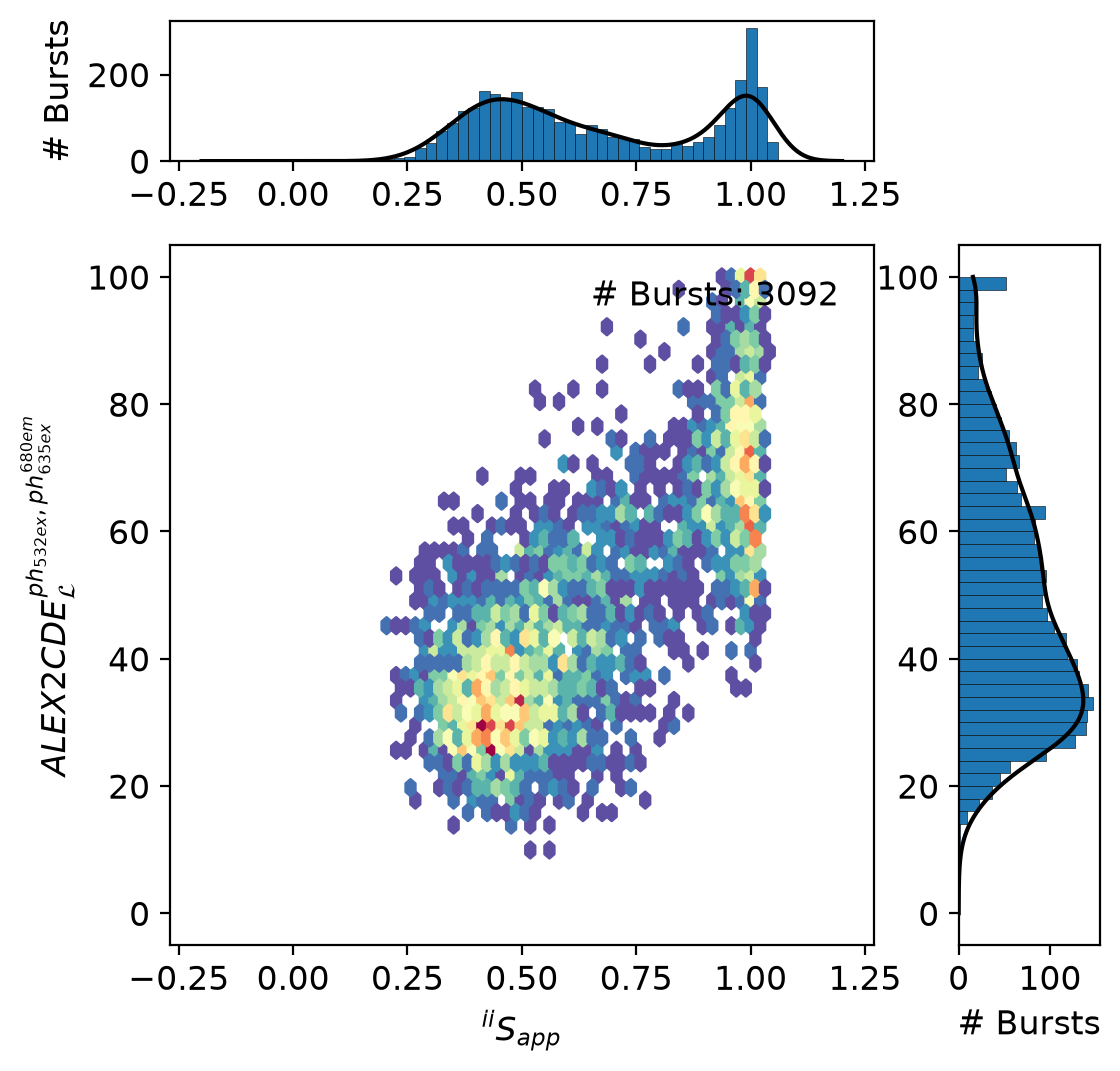

In [24]:
# valid = np.isfinite(ALEX_2CDE)
# print('Number of bursts (removing NaNs/Infs):', valid.sum())
# g = sns.JointGrid(x=ds1.S[0][valid], y=ALEX_2CDE[valid], ratio=3)
# g = g.plot_joint(plt.hexbin, **{'cmap': 'Spectral_r', 'mincnt': 1, 'gridsize': 40})
# _ = g.ax_marg_x.hist(ds1.S[0][valid], bins=np.arange(0, 1.2, 0.0333), **hist_kws)
# _ = g.ax_marg_y.hist(ALEX_2CDE[valid], bins=40, orientation="horizontal", **hist_kws)
# g.ax_joint.set_xlabel('S', fontsize=16)
# g.ax_joint.set_ylabel('ALEX-2CDE', fontsize=16)
# g.ax_joint.text(0.95, 0.95, '# Bursts: %d' % valid.sum(), 
#                 va='top', ha='right', transform=g.ax_joint.transAxes);

fig = plt.figure(figsize=(6,6))
# kwargs for central plot, 
alex_hexbin_kwargs = {'cmap':'Spectral_r', 'mincnt':1, 'gridsize':40}
hist_kwargs = {'edgecolor':'k', 'linewidth':0.2, 'kdeplot_kwargs':{'c':'k'}}
xhist_kwargs = {'bins':np.linspace(-0.2, 1.2, 61)}
yhist_kwargs = {'bins':np.linspace(0, 100, 51)}

jp = smf.plot.jointplot(data, bursts['S_bg'], Alex2CDE_l, gate=gDD, fig=fig,
                        cfunc=smf.plot.hexbin, hfunc=smf.plot.hist_kdeoverlay,
                        cplot_kwargs=alex_hexbin_kwargs, 
                        hplot_kwargs=hist_kwargs, 
                        xplot_kwargs=xhist_kwargs, yplot_kwargs=yhist_kwargs)

nburst = np.isfinite(data.get_column(Alex2CDE_l, gate=gDD)).sum()
jp[0][0].text(0.95, 0.95, f'# Bursts: {nburst}', 
              va='top', ha='right', transform=jp[0][0].transAxes);

We can now use this to build gates based on the 2CDE values.

In [25]:
# masks = [valid * (ALEX_2CDE < 88) * (ds1.S[0] > 0.9)]
# ds2 = ds1.select_bursts_mask_apply(masks)

# Alex2CDE based gate note: repeating value of old notbook, better value is 40
gA2CDE = smf.make_lt_gate(Alex2CDE_l, 88.0)
gDonly = smf.make_geq_gate(bursts['S_bg'], 0.9)
gA2CDE_S = gDD & gA2CDE & gDonly

And plot those just like any other column.

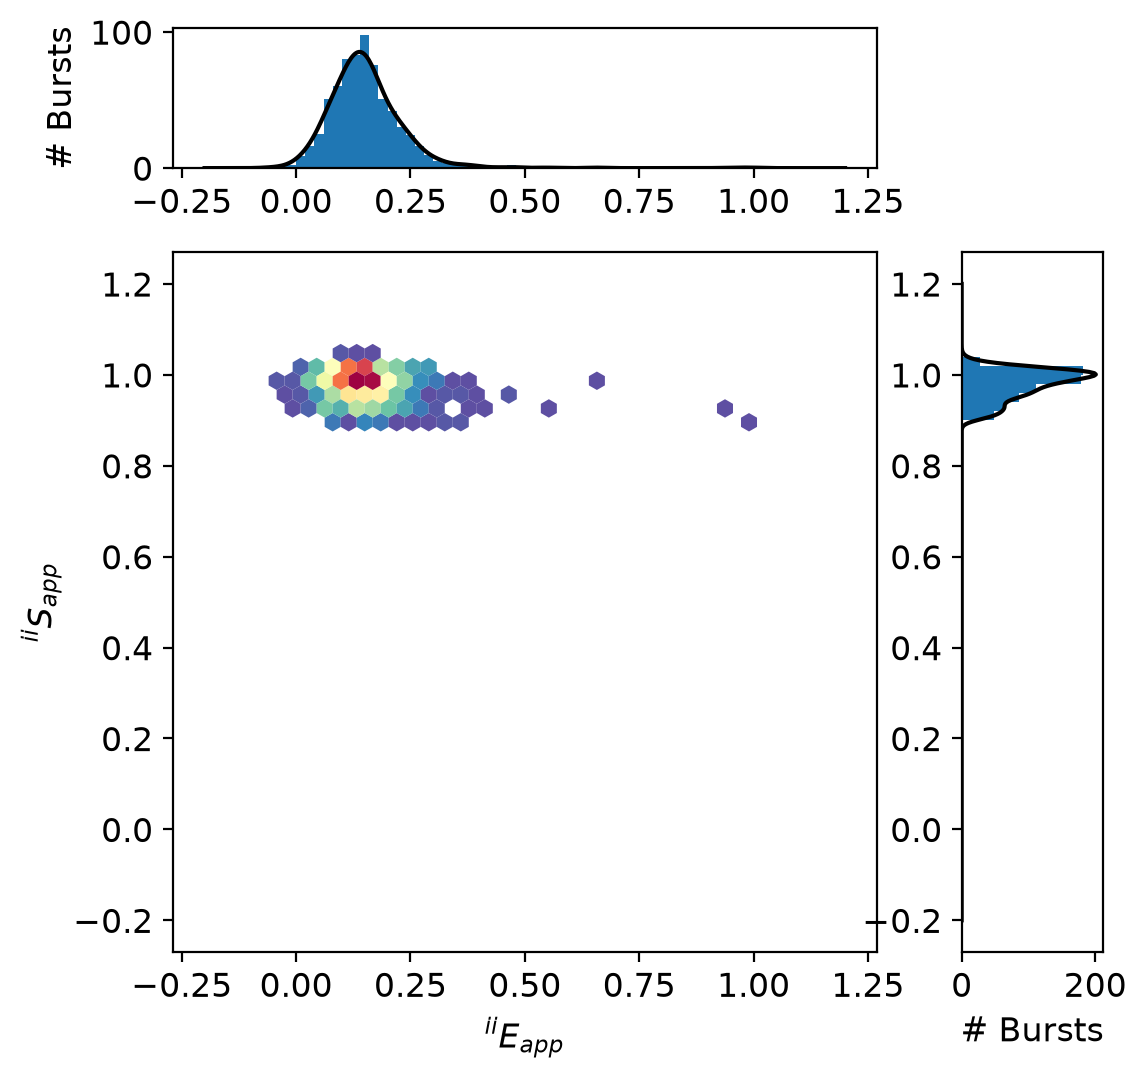

In [26]:
# alex_jointplot(ds2, vmax_fret=False);

fig = plt.figure(figsize=(6,6))

cplot_kwargs= smf.ff.AD['hexbin', ('cmap', 'Spectral_r')]
hplot_kwargs={'bins':smf.ff.AD['ratio_bins'], 'kdeplot_kwargs':{'c':'k'}}

smf.plot.jointplot(data, bursts['E_bg'], bursts['S_bg'], 
                   gate=gA2CDE_S, fig=fig,
                   cfunc=smf.plot.hexbin, cplot_kwargs=cplot_kwargs,
                   hfunc=smf.plot.hist_kdeoverlay, hplot_kwargs=hplot_kwargs,);

## New in smfBursts

Don't forget to print your citations:

In [27]:
smf.print_citations()

1. Ingargiola, A., Lerner, E., Chung, S. Y., Weiss, S. & Michalet, X.
    FRETBursts: An open source toolkit for analysis of freely-diffusing Single-
    molecule FRET. PLoS ONE 11, 1–27 (2016).
2. Kapanidis, A. N. et al. Alternating-Laser Excitation of Single Molecules.
    Accounts of Chemical Research 38, 523–533 (2005).
3. Eggeling, C., Fries, J. R., Brand, L., Günther, R. & Seidel, C. A. M.
    Monitoring conformational dynamics of a single molecule by selective
    fluorescence spectroscopy. Proc. Natl. Acad. Sci. U.S.A. 95, 1556–1561
    (1998).
4. Fries, J. R., Brand, L., Eggeling, C., Köllner, M. & Seidel, C. A. M.
    Quantitative Identification of Different Single Molecules by Selective Time-
    Resolved Confocal Fluorescence Spectroscopy. J. Phys. Chem. A 102, 6601–6613
    (1998).
5. Tomov, T. E. et al. Disentangling subpopulations in single-molecule FRET and
    ALEX experiments with photon distribution analysis. Biophysical Journal 102,
    1163–1173 (2012).


And get the parameter descriptions:

In [28]:
print(Fret2CDE_l.regate(gMain).description)

Column: KDE, fret2cde, 0ex0em, 0ex1em
  Params:
    kernel: smfbursts.childphotontables.laplace_kde
    thresh: 0.00025
    all_phot: False
    exclude_zero: True
    tau: 5e-05
  Parents:
    base:  Table: Bursts
      Params:
        func: smfbursts.bursttables.burstsearch_mwindowF_bg
        stream: 0ex_1em
        m: 10
        F: 6.0
        c: -1.0
        fuse: 0.0
      Parents:
        bg:  Table: BG
          Params:
            compute_stream: single_all
            func: smfbursts.backgroundtables.exp_mlefit
            tail_min: [0.0005 0.0005 0.0005 0.0005 0.0005]
            auto_threshold: True
            F_bg: 1.7
          Parents:
            base:  Table: Periods
              Params:
                period: 20.0
                start_at: time_min
                stop_at: over
                detdef: DetDef2ex2em
  GateGroup:
    truthtable: [[False False]
                 [False  True]]
    Gates:
      - Gate: smfbursts.datamodel.gates.linear_geq_gate
        Par

In [29]:
print(Fret2CDE_g.regate(gMain).description)

Column: KDE, fret2cde, 0ex0em, 0ex1em
  Params:
    kernel: smfbursts.childphotontables.gaussian_kde
    thresh: 0.00025
    all_phot: True
    exclude_zero: True
    sigma: 5e-05
  Parents:
    base:  Table: Bursts
      Params:
        func: smfbursts.bursttables.burstsearch_mwindowF_bg
        stream: 0ex_1em
        m: 10
        F: 6.0
        c: -1.0
        fuse: 0.0
      Parents:
        bg:  Table: BG
          Params:
            compute_stream: single_all
            func: smfbursts.backgroundtables.exp_mlefit
            tail_min: [0.0005 0.0005 0.0005 0.0005 0.0005]
            auto_threshold: True
            F_bg: 1.7
          Parents:
            base:  Table: Periods
              Params:
                period: 20.0
                start_at: time_min
                stop_at: over
                detdef: DetDef2ex2em
  GateGroup:
    truthtable: [[False False]
                 [False  True]]
    Gates:
      - Gate: smfbursts.datamodel.gates.linear_geq_gate
        P

In [30]:
print(Alex2CDE_l.regate(gDD).description)

Column: KDE, alex2cde, 1ex1em, 0ex
  Params:
    kernel: smfbursts.childphotontables.laplace_kde
    thresh: 0.00025
    all_phot: False
    exclude_zero: True
    tau: 5e-05
  Parents:
    base:  Table: Bursts
      Params:
        func: smfbursts.bursttables.burstsearch_mwindowF_bg
        stream: 0ex_1em
        m: 10
        F: 6.0
        c: -1.0
        fuse: 0.0
      Parents:
        bg:  Table: BG
          Params:
            compute_stream: single_all
            func: smfbursts.backgroundtables.exp_mlefit
            tail_min: [0.0005 0.0005 0.0005 0.0005 0.0005]
            auto_threshold: True
            F_bg: 1.7
          Parents:
            base:  Table: Periods
              Params:
                period: 20.0
                start_at: time_min
                stop_at: over
                detdef: DetDef2ex2em
  GateGroup:
    truthtable: [False  True]
    Gates:
      - Gate: smfbursts.datamodel.gates.linear_geq_gate
        Params:
          vec: [1.]
          m

This is the end of this notebook.